# Montessori Teacher Training Programs Worldwide, Starter Notebook

![cover](https://raw.githubusercontent.com/montessoritheory/montessori-teacher-training-programs/main/images/cover.png)

This notebook loads the dataset and answers four quick questions about Montessori teacher training. Programs come from the MACTE accredited program search and the AMI list of training centres. Companion directory with a page per country, [Montessori School Finder](https://www.montessorischoolfinder.com/montessori-certifications/training-centers/). Dataset by [Montessori Theory](https://www.montessori-theory.com/) and Montessori School Finder, CC BY 4.0.

In [1]:
import os, pandas as pd, matplotlib.pyplot as plt

# works on Kaggle, locally, and straight from GitHub
KAGGLE = "/kaggle/input/montessori-teacher-training-programs"
LOCAL = next((p for p in ["data", "../data"] if os.path.exists(p)), "data")
GITHUB = "https://raw.githubusercontent.com/montessoritheory/montessori-teacher-training-programs/main/data"
base = KAGGLE if os.path.exists(KAGGLE) else LOCAL if os.path.exists(LOCAL) else GITHUB
sep = "/" if base != LOCAL else os.sep
read = lambda name: pd.read_csv(base + sep + name)

programs = read("programs.csv").fillna("")
by_country = read("by_country.csv")
programs.shape

(356, 26)

In [2]:
plt.rcParams.update({"figure.facecolor": "#f8fafc", "axes.facecolor": "white", "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.color": "#e2e8f0", "font.size": 12})
INK, BLUE, GREEN = "#0f172a", "#2563eb", "#059669"

## 1. How many programs, and where?

`listed_by` says which list a program is on. A program can be on both.

In [3]:
print(len(programs), "programs in", programs.country.nunique(), "countries")
programs.listed_by.value_counts()

356 programs in 56 countries


listed_by
MACTE            244
AMI              103
MACTE and AMI      9
Name: count, dtype: int64

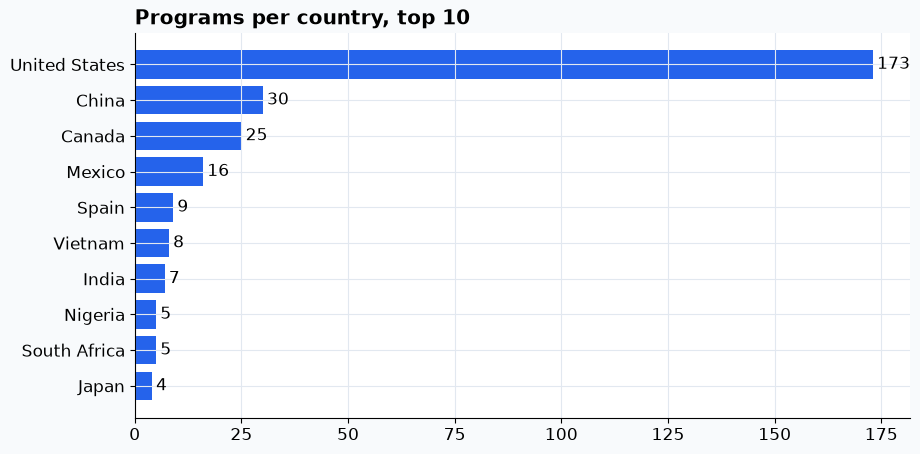

,rank,country,programs,macte_listed,ami_listed,both
0,1,United States,173,165,16,8
1,2,China,30,25,5,0
2,3,Canada,25,22,3,0
3,4,Mexico,16,4,13,1
4,5,Spain,9,0,9,0
5,6,Vietnam,8,6,2,0
6,7,India,7,0,7,0
7,8,Nigeria,5,4,1,0
8,9,South Africa,5,4,1,0
9,10,Japan,4,1,3,0


In [4]:
top = by_country.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(top.country, top.programs, color=BLUE)
for y, v in enumerate(top.programs): ax.text(v + 1, y, v, va="center")
ax.set_title("Programs per country, top 10", loc="left", fontweight="bold")
plt.show()
by_country[["rank", "country", "programs", "macte_listed", "ami_listed", "both"]].head(10)

## 2. Which levels can you train for?

MACTE gives levels. The AMI list mostly does not, so 101 AMI-only centres have `levels_published` set to False.

In [5]:
has = programs[programs.levels_published]
flags = ["level_infant_toddler", "level_early_childhood", "level_elementary", "level_secondary"]
levels = has[flags].sum().rename(lambda s: s.replace("level_", "").replace("_", " ").title())
print(len(has), "programs publish levels")
levels

255 programs publish levels


Infant Toddler      87
Early Childhood    205
Elementary          91
Secondary           13
dtype: int64

## 3. MACTE accredited programs by delivery format

`delivery_format` is MACTE's share of hours online.

In [6]:
macte = programs[programs.macte_listed]
macte.delivery_format.replace("", "Not published").value_counts()

delivery_format
More than 90% In-Person    104
10-50% Online               74
More than 50% Online        71
Not published                4
Name: count, dtype: int64

## 4. Find a program

Early Childhood programs outside the United States, with the Montessori School Finder page to read more.

In [7]:
found = programs[programs.level_early_childhood & (programs.country != "United States")]
found[["name", "city", "country", "listed_by", "msf_url"]].sort_values(["country", "city"]).head(15)

,name,city,country,listed_by,msf_url
3,Australian Montessori Training Institute,Maroubra,Australia,MACTE,https://www.montessorischoolfinder.com/montess...
7,Centro de Educacao Montessori de Sao Paulo,Santana de Parnaiba,Brazil,MACTE,https://www.montessorischoolfinder.com/montess...
21,Montessori Teachers College,Brampton,Canada,MACTE,https://www.montessorischoolfinder.com/montess...
12,Montessori Teachers College,Calgary,Canada,MACTE,https://www.montessorischoolfinder.com/montess...
22,Canadian Montessori Teacher Education Institute,Markham,Canada,MACTE,https://www.montessorischoolfinder.com/montess...
23,Canadian Montessori Teacher Education Institute,Mississauga,Canada,MACTE,https://www.montessorischoolfinder.com/montess...
31,Canadian Montessori Teacher Education Institute,Montréal,Canada,MACTE,https://www.montessorischoolfinder.com/montess...
25,Canadian Montessori Teacher Education Institute,Ottawa,Canada,MACTE,https://www.montessorischoolfinder.com/montess...
26,Montessori Mantra Teachers' Training College,Pickering,Canada,MACTE,https://www.montessorischoolfinder.com/montess...
13,Canadian Southwestern College Montessori Teach...,Richmond,Canada,MACTE,https://www.montessorischoolfinder.com/montess...


## Read With Care

- This is a snapshot of two public listings read in November 2026. Check dates, fees and entry rules with each program.
- `macte_status` copies what MACTE shows. A program that is not MACTE listed may still be recognized elsewhere.
- Coordinates are city centres, not street addresses.

Credit **Montessori Theory** and **Montessori School Finder** (CC BY 4.0), and the MACTE and AMI listings as sources.